# Prevision day-ahead du prix de l'electricite en Allemagne

Ce notebook construit une prevision du prix day-ahead : au moment de predire les 24 heures du lendemain, seules les observations disponibles au plus tard 24 heures avant sont utilisees.

La cible est `DE_price_day_ahead`, exprimee en EUR/MWh. Les prix de l'annee 2005 a avril 2019 couvrent une longue periode durant laquelle le marche allemand a fortement evolue, notamment avec la progression de l'eolien et du solaire.

In [ ]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

DATA_PATH = Path('../data/time_series_60min_singleindex.csv')
OUTPUT_DIR = Path('../outputs')
TIMESTAMP = 'utc_timestamp'
TARGET = 'DE_price_day_ahead'
# Uniquement des informations disponibles avant le jour a predire.
LAGS = (24, 48, 72, 168)
ROLLING_WINDOWS = (24, 168)
OUTPUT_DIR.mkdir(exist_ok=True)

## 1. Chargement et controle qualite

In [2]:
data = pd.read_csv(
    DATA_PATH,
    usecols=[TIMESTAMP, TARGET],
    parse_dates=[TIMESTAMP],
).set_index(TIMESTAMP).sort_index()
data = data.rename(columns={TARGET: 'price_eur_mwh'})
data['price_eur_mwh'] = pd.to_numeric(data['price_eur_mwh'], errors='coerce')

print(f'Nombre total de lignes dans le fichier : {len(data):,}')
print(f'Premiere date du fichier : {data.index.min()}')
print(f'Derniere date du fichier : {data.index.max()}')
print(f'Doublons temporels : {data.index.duplicated().sum()}')
print(f'Valeurs manquantes du prix : {data.price_eur_mwh.isna().mean() * 100:.2f}%')
print(f'Prix minimum : {data.price_eur_mwh.min():.2f} EUR/MWh')
print(f'Prix maximum : {data.price_eur_mwh.max():.2f} EUR/MWh')

# L'index UTC est regularise afin que shift(24) signifie bien 24 heures.
data = data.asfreq('h')
print(f'Observations de prix utilisables : {data.price_eur_mwh.notna().sum():,}')
data.describe()

Nombre total de lignes dans le fichier : 125,593
Premiere date du fichier : 2004-12-31 23:00:00+00:00
Derniere date du fichier : 2019-04-30 23:00:00+00:00
Doublons temporels : 0
Valeurs manquantes du prix : 0.53%
Prix minimum : -500.02 EUR/MWh
Prix maximum : 2436.63 EUR/MWh
Observations de prix utilisables : 124,927


,price_eur_mwh
count,124927.000000
mean,41.970970
std,24.723946
min,-500.020000
25%,29.110000
50%,39.100000
75%,51.680000
max,2436.630000


## 2. Exploration de la serie allemande

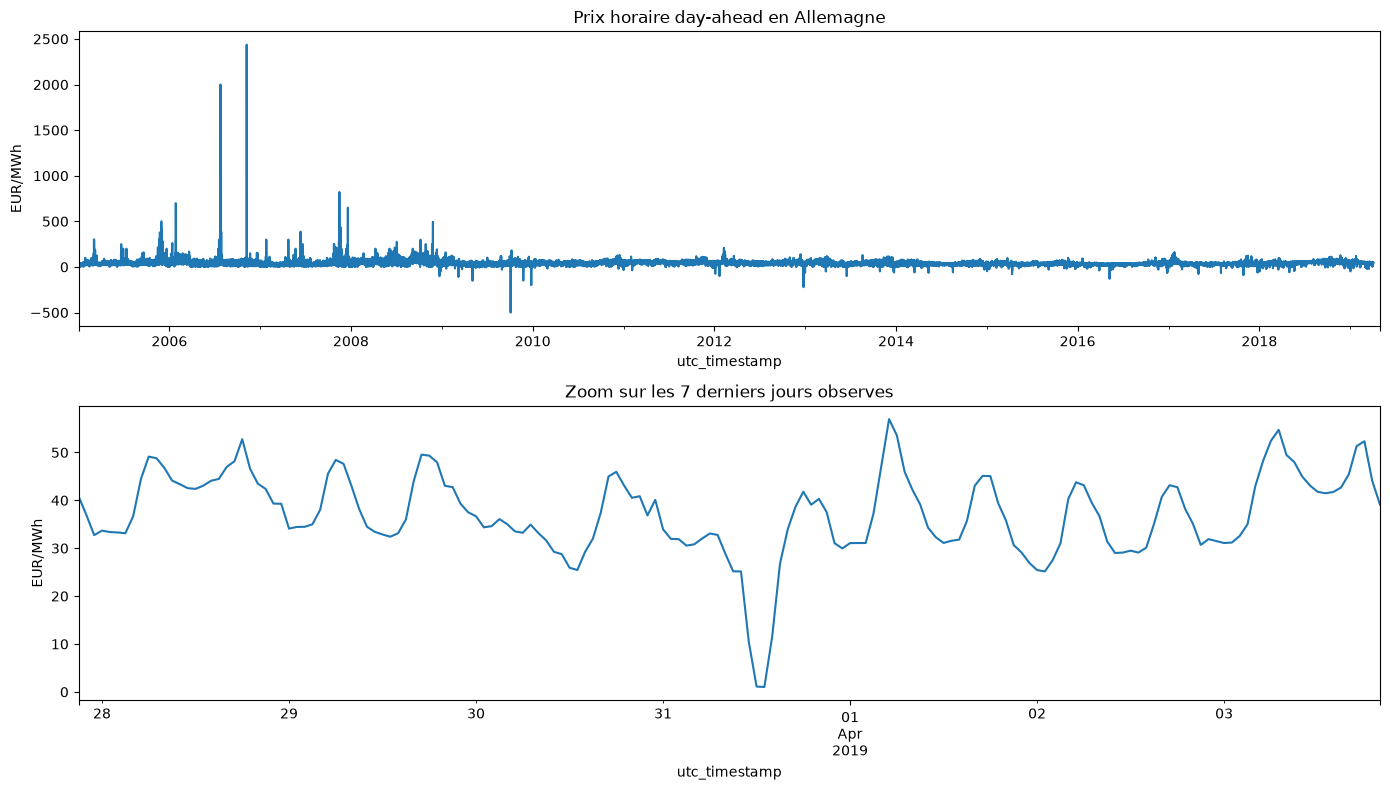

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8))
data.price_eur_mwh.plot(ax=axes[0], title='Prix horaire day-ahead en Allemagne')
axes[0].set_ylabel('EUR/MWh')

observed_data = data.dropna(subset=['price_eur_mwh'])
last_week = observed_data.iloc[-7 * 24:]
last_week.price_eur_mwh.plot(ax=axes[1], title='Zoom sur les 7 derniers jours observes')
axes[1].set_ylabel('EUR/MWh')
plt.tight_layout()
plt.show()

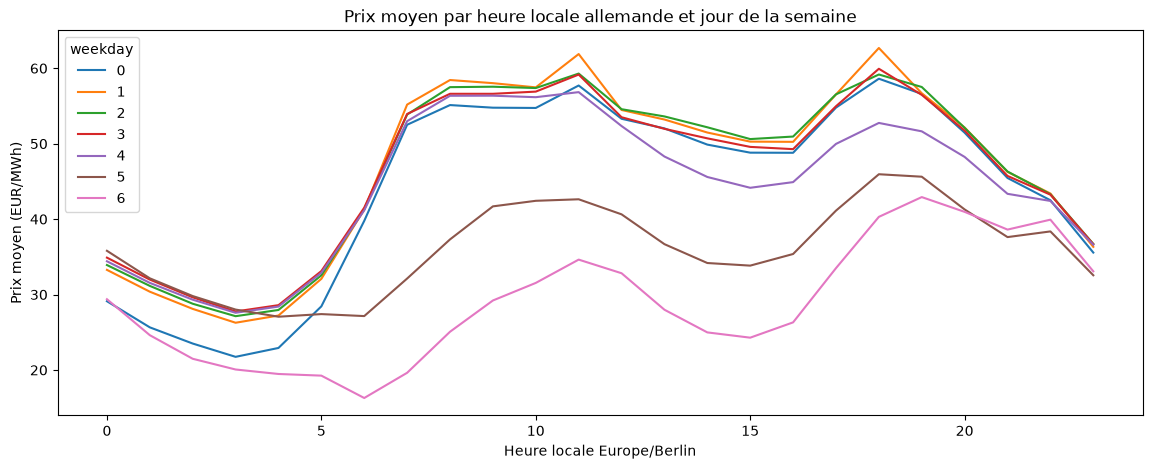

In [5]:
local_data = data.tz_convert('Europe/Berlin')
exploration = local_data.assign(
    hour=local_data.index.hour,
    weekday=local_data.index.day_of_week,
).groupby(['weekday', 'hour']).price_eur_mwh.mean().unstack(0)
exploration.plot(figsize=(14, 5), title='Prix moyen par heure locale allemande et jour de la semaine')
plt.xlabel('Heure locale Europe/Berlin')
plt.ylabel('Prix moyen (EUR/MWh)')
plt.show()

## 3. Creation des variables explicatives

Les variables calendaires sont cycliques pour representer correctement le passage de 23 h a 0 h. Les retards et moyennes mobiles du prix sont decales : aucune information du futur n'est introduite.

In [6]:
features = pd.DataFrame(index=data.index)
hour = data.index.hour + data.index.minute / 60
weekday = data.index.day_of_week
day_of_year = data.index.day_of_year

features['hour_sin'] = np.sin(2 * np.pi * hour / 24)
features['hour_cos'] = np.cos(2 * np.pi * hour / 24)
features['weekday_sin'] = np.sin(2 * np.pi * weekday / 7)
features['weekday_cos'] = np.cos(2 * np.pi * weekday / 7)
features['year_progress_sin'] = np.sin(2 * np.pi * day_of_year / 365.25)
features['year_progress_cos'] = np.cos(2 * np.pi * day_of_year / 365.25)
features['is_weekend'] = (weekday >= 5).astype(int)

for lag in LAGS:
    features[f'price_lag_{lag}h'] = data.price_eur_mwh.shift(lag)

# Ces statistiques utilisent uniquement les prix connus avant le jour a predire.
previous_day = data.price_eur_mwh.shift(24)
for window in ROLLING_WINDOWS:
    features[f'price_mean_{window}h'] = previous_day.rolling(window).mean()
    features[f'price_std_{window}h'] = previous_day.rolling(window).std()

features = features.join(data.price_eur_mwh).dropna()
feature_columns = [column for column in features.columns if column != 'price_eur_mwh']
print(f'Variables explicatives : {len(feature_columns)}')
features.head()

Variables explicatives : 15


,hour_sin,hour_cos,weekday_sin,weekday_cos,year_progress_sin,year_progress_cos,is_weekend,price_lag_24h,price_lag_48h,price_lag_72h,price_lag_168h,price_mean_24h,price_std_24h,price_mean_168h,price_std_168h,price_eur_mwh
utc_timestamp,,,,,,,,,,,,,,,,
2005-01-08 23:00:00+00:00,-0.258819,0.965926,-0.974928,-0.222521,0.137185,0.990545,1,21.43,24.80,22.51,11.35,27.934167,7.777609,25.505000,10.178905,14.86
2005-01-09 00:00:00+00:00,0.000000,1.000000,-0.781831,0.623490,0.154204,0.988039,1,16.19,16.77,22.33,7.11,27.910000,7.814620,25.482024,10.195634,11.52
2005-01-09 01:00:00+00:00,0.258819,0.965926,-0.781831,0.623490,0.154204,0.988039,1,15.43,13.45,18.19,6.90,27.992500,7.664333,25.484583,10.193041,7.57
2005-01-09 02:00:00+00:00,0.500000,0.866025,-0.781831,0.623490,0.154204,0.988039,1,6.93,12.71,13.95,5.84,27.751667,8.234994,25.446012,10.251101,7.00
2005-01-09 03:00:00+00:00,0.707107,0.707107,-0.781831,0.623490,0.154204,0.988039,1,2.51,12.51,13.91,6.68,27.335000,9.232303,25.379226,10.363817,6.98


## 4. Separation temporelle

On ne melange pas les observations : les 80 % les plus anciennes servent a l'entrainement et les 20 % les plus recentes servent au test.

In [7]:
split_index = int(len(features) * 0.80)
test = features.iloc[split_index:]
train = features.iloc[:split_index]

print(f'Entrainement historique : {train.index.min()} -> {train.index.max()}')
print(f'Test : {test.index.min()} -> {test.index.max()}')
print(f'Taille train/test : {len(train):,} / {len(test):,}')

# Fenetre glissante : les trois annees precedant le debut du test.
rolling_start = test.index.min() - pd.DateOffset(years=3)
rolling_train = train.loc[train.index >= rolling_start]
print(f'Entrainement fenetre glissante 3 ans : {rolling_train.index.min()} -> {rolling_train.index.max()}')
print(f'Taille fenetre glissante : {len(rolling_train):,}')

Entrainement historique : 2005-01-08 23:00:00+00:00 -> 2016-05-27 20:00:00+00:00
Test : 2016-05-27 21:00:00+00:00 -> 2019-04-03 20:00:00+00:00
Taille train/test : 97,907 / 24,477
Entrainement fenetre glissante 3 ans : 2013-05-27 21:00:00+00:00 -> 2016-05-27 20:00:00+00:00
Taille fenetre glissante : 25,797


## 5. Baseline et modele de machine learning

La baseline utilise le prix de la meme heure la veille. Le modele day-ahead utilise uniquement des retards d'au moins 24 heures et des statistiques construites a partir de la journee precedente ou de jours plus anciens.

In [8]:
def build_model():
    return HistGradientBoostingRegressor(
        learning_rate=0.05,
        max_iter=300,
        max_leaf_nodes=31,
        l2_regularization=1.0,
        random_state=42,
    )


def metrics(actual, prediction, baseline_mae):
    actual = np.asarray(actual)
    prediction = np.asarray(prediction)
    smape_denominator = np.abs(actual) + np.abs(prediction)
    valid_smape = smape_denominator != 0
    smape = 2 * np.abs(actual - prediction) / smape_denominator
    model_mae = mean_absolute_error(actual, prediction)
    return {
        'MAE_EUR_MWh': model_mae,
        'RMSE_EUR_MWh': np.sqrt(mean_squared_error(actual, prediction)),
        'sMAPE_percent': smape[valid_smape].mean() * 100,
        'amelioration_vs_baseline_percent': (1 - model_mae / baseline_mae) * 100,
    }


baseline = test.price_lag_24h.to_numpy()
baseline_mae = mean_absolute_error(test.price_eur_mwh, baseline)

historical_model = build_model()
historical_model.fit(train[feature_columns], train.price_eur_mwh)
predicted_historical = historical_model.predict(test[feature_columns])

rolling_model = build_model()
rolling_model.fit(rolling_train[feature_columns], rolling_train.price_eur_mwh)
predicted_rolling = rolling_model.predict(test[feature_columns])

metrics_table = pd.DataFrame({
    'baseline_meme_heure_j-1': {
        'MAE_EUR_MWh': baseline_mae,
        'RMSE_EUR_MWh': np.sqrt(mean_squared_error(test.price_eur_mwh, baseline)),
        'sMAPE_percent': metrics(test.price_eur_mwh, baseline, baseline_mae)['sMAPE_percent'],
        'amelioration_vs_baseline_percent': 0.0,
    },
    'modele_historique': metrics(test.price_eur_mwh, predicted_historical, baseline_mae),
    'modele_fenetre_3_ans': metrics(test.price_eur_mwh, predicted_rolling, baseline_mae),
}).T
metrics_table.round(2)

,MAE_EUR_MWh,RMSE_EUR_MWh,sMAPE_percent,amelioration_vs_baseline_percent
baseline_meme_heure_j-1,9.46,14.47,31.26,0.00
modele_historique,7.34,11.37,23.66,22.41
modele_fenetre_3_ans,9.03,12.72,28.40,4.59


## 6. Visualisation et sauvegarde des resultats

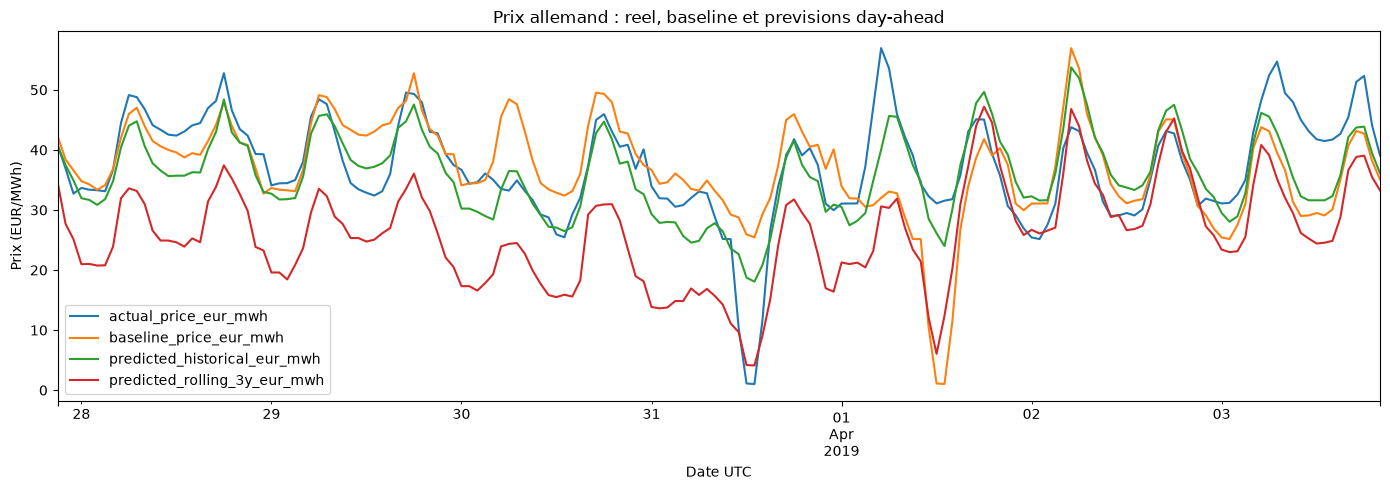

Resultats sauvegardes dans : /home/noudegbessi/Documents/Projet/Energie_project/script/outputs


In [9]:
predictions = pd.DataFrame({
    'actual_price_eur_mwh': test.price_eur_mwh,
    'baseline_price_eur_mwh': baseline,
    'predicted_historical_eur_mwh': predicted_historical,
    'predicted_rolling_3y_eur_mwh': predicted_rolling,
}, index=test.index)

predictions.iloc[-7 * 24:].plot(figsize=(14, 5), title='Prix allemand : reel, baseline et previsions day-ahead')
plt.ylabel('Prix (EUR/MWh)')
plt.xlabel('Date UTC')
plt.tight_layout()
plt.show()

metrics_table.to_csv(OUTPUT_DIR / 'metrics_price_germany_day_ahead.csv')
predictions.to_csv(OUTPUT_DIR / 'predictions_price_germany_day_ahead.csv')
joblib.dump(
    {'model': rolling_model, 'feature_columns': feature_columns, 'training_window': '3 years'},
    OUTPUT_DIR / 'germany_price_day_ahead_model.joblib',
)
print(f'Resultats sauvegardes dans : {OUTPUT_DIR.resolve()}')

## 7. Limites et prochaines ameliorations

- Cette version respecte la contrainte day-ahead : les variables de prix sont toutes decalees d'au moins 24 heures.
- Les prix 2005 a avril 2019 melangent des regimes de marche differents ; la comparaison avec une fenetre glissante de trois ans est donc plus representative qu'un entrainement sur toute l'histoire.
- Ajouter la demande electrique prevue, la production solaire/eolienne prevue, les capacites disponibles et les prix des combustibles.
- Ajouter la temperature, la meteo, les jours feries allemands et les vacances scolaires.
- Les prix negatifs et les pics extremes rendent le MAPE peu interpretable ; on conserve MAE, RMSE et sMAPE, ainsi que l'amelioration relative a la baseline.
- Tester une validation temporelle glissante sur plusieurs dates de coupure et une recherche d'hyperparametres.
- Tenir compte du fuseau horaire local allemand pour les variables calendaires et les analyses de profil ; les donnees de prix restent horodatees en UTC pour le modele.

La cellule de chargement affiche la periode exacte du fichier et le minimum/maximum des prix. Une evaluation sur des donnees plus recentes est necessaire avant une utilisation operationnelle.